# Task 3 -- Parameter-Efficient Fine-Tuning (Iteration 1)
### BITS Pilani WILP M.Tech. AIML -- Conversational AI (AIMLCZG521) -- PS2

| Field | Value |
|---|---|
| **Notebook** | 03 of 05 -- Task 3: Parameter-Efficient Fine-Tuning, Iteration 1 (2.5 marks, core) |
| **Technique** | LoRA (Low-Rank Adaptation) on top of a bf16-loaded base model |
| **Base model** | `Qwen/Qwen2.5-1.5B-Instruct` |
| **Output** | Adapter `models/novabank-slm-lora-v1/` -- this run's model is **Version 1 (v1)** |

**MUST RUN IN THE BITS VIRTUAL LAB** (GPU required for training in reasonable time; a full epoch over
286 examples on CPU is impractical). Take full-screen screenshots while it runs, per PS2's Virtual Lab
proof requirement. This notebook was authored and syntax-checked outside the Virtual Lab; **all shown
outputs, loss curves and the saved adapter must come from an actual Virtual Lab execution.**

## Problem Understanding

Task 2 established a quality gap between the unmodified SLM (A) and the reference LLM (B). This
notebook closes part of that gap by parameter-efficiently fine-tuning the SLM on the 286-example
NovaBank training split (Notebook 01), producing **Version 1 (v1)** -- the first of the two required
fine-tuning iterations (Task 4 diagnoses v1 and produces v2).

## Theory: Why LoRA Is Parameter-Efficient

**Intuition.** A pretrained weight matrix $W \in \mathbb{R}^{d \times k}$ already encodes broad
language competence. Adapting it to a narrow domain does not need a full new $d \times k$ matrix of
free parameters -- empirically, the *change* required, $\Delta W$, tends to have low "intrinsic rank":
most of the useful adaptation lives in a small subspace. LoRA exploits this directly: instead of
updating $W$, it freezes $W$ and adds a low-rank correction

$$ W' = W + \frac{\alpha}{r} B A, \qquad A \in \mathbb{R}^{r \times k},\; B \in \mathbb{R}^{d \times r},\; r \ll \min(d, k) $$

Only $A$ and $B$ are trained. If $d = k = 1536$ (a typical Qwen2.5-1.5B hidden size) and $r = 8$, one
adapted matrix needs $2 \times 8 \times 1536 = 24{,}576$ trainable parameters instead of $1536^2
\approx 2.36$M for full fine-tuning of that matrix alone -- **about 1% of the parameters, for that
matrix.** Applied only to the attention projections (`q_proj, k_proj, v_proj, o_proj`) across all
layers, this is what produces the sub-1%-of-total trainable-parameter figure measured below.

**Why this also saves *memory*, not just parameter count.** Adam-family optimizers keep two extra
buffers (first/second moment estimates) per *trainable* parameter, in fp32. With <1% of parameters
trainable, optimizer state shrinks by roughly the same factor, and gradients only need to be computed
and stored for the LoRA matrices, not the full frozen base model. Loading the frozen base model itself
in 4-bit (the "Q" in QLoRA, via `bitsandbytes`) additionally cuts the (much larger) frozen-weight memory
by ~4x relative to fp16/bf16 -- combined, this is what lets a 1.5B model fine-tune on a single modest
GPU where full fine-tuning would not fit.

**AI/ML engineering relevance.** This is the same mechanism used in practice to fine-tune 7B-70B
models on a single consumer/workstation GPU, and to serve many task-specific "adapters" against one
shared frozen base model in production (swap the small adapter, not the whole model).

**Exam/interview angle.** Be ready to state: (1) the low-rank decomposition formula and what $r$,
$\alpha$ control; (2) why Adam's memory cost scales with *trainable* parameters, not total; (3) the
difference between LoRA (frozen bf16/fp16 base) and QLoRA (frozen base additionally quantised to 4-bit).

## Imports and Environment Setup

In [1]:
import sys, os, json, time
sys.path.insert(0, os.path.abspath(".."))

# If running in the Virtual Lab for the first time, uncomment:
# %pip install -q transformers accelerate peft bitsandbytes torch datasets

import numpy as np
import torch
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

from src.config import (SLM_MODEL_ID, SEED, PROCESSED_DIR, ADAPTER_V1_DIR,
                          RESULTS_DIR, GENERATION_KWARGS, SYSTEM_PROMPT, BENCHMARK_PATH)
from src.data_utils import load_split, load_benchmark, format_chat_prompt, format_training_example
from src.model_utils import load_causal_lm, count_trainable_parameters, peak_gpu_memory_mb, generate_response
from src.train_utils import build_lora_config, build_tokenized_dataset, plot_loss_curves
from src.eval_utils import save_json

# --- Reproducibility: fix every RNG this training run touches -------------------
random_seed = SEED
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


W0811 23:44:55.207000 38172 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## Load Data (train/val splits from Notebook 01)

In [2]:
train_records = load_split(PROCESSED_DIR, "train")
val_records = load_split(PROCESSED_DIR, "val")
print(f"train={len(train_records)}  val={len(val_records)}")
print("Example:", train_records[0])


train=286  val=26
Example: {'instruction': 'I need to see my account fees, where do I do it?', 'input': '', 'output': 'I can assist you with that. To view your account fees, you can easily access them by following these steps:\n\n1. Log in to your account on our website or mobile app.\n2. Navigate to the "Account" or "Profile" section.\n3. Look for an option like "Account Fees" or "Billing" and click on it.\n4. You should be able to see a breakdown of your account fees, including any applicable charges.\n\nIf you encounter any issues or have further questions about your account fees, please don\'t hesitate to let me know.', 'category': 'FEES', 'intent': 'check_fees'}


## Load Base Model in 4-bit (QLoRA-style) + Attach LoRA Adapter

`quantize_4bit=True` loads the frozen base weights in 4-bit NF4 precision -- this is the "Q" of QLoRA.
`prepare_model_for_kbit_training` (peft) then does the bookkeeping quantised training needs
(casts norms to fp32 for stability, enables gradient checkpointing hooks, etc.) before LoRA adapters
are attached on top.

In [3]:
from peft import get_peft_model, prepare_model_for_kbit_training

base_model, tokenizer = load_causal_lm(SLM_MODEL_ID, quantize_4bit=True)
base_model = prepare_model_for_kbit_training(base_model)

lora_config = build_lora_config(r=8, alpha=16, dropout=0.05)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


## Efficiency Evidence (mandatory for Task 3)

**(a) Trainable vs. total parameters.**

In [4]:
param_stats = count_trainable_parameters(model)
print(json.dumps(param_stats, indent=2))
save_json(param_stats, os.path.join(RESULTS_DIR, "task3_param_efficiency.json"))


{
  "trainable_params": 2179072,
  "total_params": 890795520,
  "trainable_pct": 0.2446
}


**(b) Peak GPU memory during training.** Reset the CUDA peak-memory counter immediately before
`.train()` and read it immediately after -- this captures the true high-water mark (activations +
gradients + optimizer state + the quantised frozen base), not just the static model size.

## Training Configuration

| Hyperparameter | Value | 1-2 line justification |
|---|---|---|
| LoRA rank `r` | 8 | Standard, well-tested starting point for <3B models on a few-hundred-example dataset; large enough to capture domain phrasing without overfitting this small a training set. |
| LoRA alpha | 16 (=2r) | The widely-used LoRA-paper default; keeps the effective update magnitude (`alpha/r`) stable if `r` is later changed. |
| LoRA dropout | 0.05 | Light regularisation against overfitting on only 286 training examples. |
| Target modules | q/k/v/o_proj | Attention projections capture most of the adaptation benefit at lowest parameter cost; adding MLP projections roughly doubles trainable params for little measured gain at this data size. |
| Learning rate | 2e-4 | Standard LoRA LR (10-100x higher than typical full-FT LR is appropriate since only the small adapter matrices are updated). |
| Epochs | 3 | With 286 examples, 3 passes give the adapter enough gradient signal to fit domain phrasing without memorising verbatim (monitored via val loss below). |
| Batch size (effective) | 8 (per-device 4 x grad-accum 2) | Fits comfortably in memory with the 4-bit base + LoRA; grad accumulation smooths noisy gradients from a small dataset. |
| Max sequence length | 512 | Covers the dataset's longest response (~403 words, well under 512 tokens of headroom) per Notebook 01's measured length distribution, without wasting memory on unnecessary padding. |
| Optimizer | `paged_adamw_8bit` | Adam-style optimizer with 8-bit paged states -- keeps the (already-small, LoRA-only) optimizer memory footprint minimal, compounding the QLoRA memory savings explained above. |

In [5]:
tokenized_train = build_tokenized_dataset(train_records, tokenizer, format_training_example, max_length=512)
tokenized_val = build_tokenized_dataset(val_records, tokenizer, format_training_example, max_length=512)
print(f"tokenized_train={len(tokenized_train)}  tokenized_val={len(tokenized_val)}")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model, label_pad_token_id=-100, padding=True)

training_args = TrainingArguments(
    output_dir=os.path.join(ADAPTER_V1_DIR, "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,  # OOM on a 6GB card (RTX 4050 Laptop / VL T4)? drop to
    # per_device_train_batch_size=2, gradient_accumulation_steps=4 -- same
    # effective batch size (8), lower peak activation memory.
    learning_rate=2e-4,
    optim="paged_adamw_8bit",
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    bf16=torch.cuda.is_available(),
    seed=random_seed,
    data_seed=random_seed,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
)


tokenized_train=286  tokenized_val=26


## Train v1 (with peak-memory measurement)

In [6]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

t0 = time.time()
train_result = trainer.train()
train_time_sec = time.time() - t0

peak_mem_mb = peak_gpu_memory_mb()
print(f"Training time: {train_time_sec/60:.1f} min")
print(f"Peak GPU memory during training: {peak_mem_mb:.0f} MB" if peak_mem_mb else "No GPU -- peak memory not measured")

efficiency_summary = {
    **param_stats,
    "peak_gpu_memory_mb": peak_mem_mb,
    "train_time_sec": train_time_sec,
    "why_full_finetuning_would_not_fit": (
        f"Full fine-tuning would make all {param_stats['total_params']:,} base parameters trainable "
        f"(100% vs. {param_stats['trainable_pct']}% here). Adam's 2 extra fp32 moment buffers per "
        "trainable parameter alone would need roughly 8 bytes x total_params just for optimizer "
        "state (~12+ GB for a 1.5B model), before gradients or activations -- multiples of the "
        f"{peak_mem_mb:.0f} MB peak measured for LoRA+4-bit above, and would not fit the 'modest "
        "hardware' budget this project targets."
    ),
}
save_json(efficiency_summary, os.path.join(RESULTS_DIR, "task3_efficiency_summary.json"))
print(json.dumps(efficiency_summary, indent=2))


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.906096,0.893693
2,0.766380,0.849714
3,0.736769,0.838958


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training time: 6.5 min
Peak GPU memory during training: 5943 MB
{
  "trainable_params": 2179072,
  "total_params": 890795520,
  "trainable_pct": 0.2446,
  "peak_gpu_memory_mb": 5943.044921875,
  "train_time_sec": 389.6837110519409,
  "why_full_finetuning_would_not_fit": "Full fine-tuning would make all 890,795,520 base parameters trainable (100% vs. 0.2446% here). Adam's 2 extra fp32 moment buffers per trainable parameter alone would need roughly 8 bytes x total_params just for optimizer state (~12+ GB for a 1.5B model), before gradients or activations -- multiples of the 5943 MB peak measured for LoRA+4-bit above, and would not fit the 'modest hardware' budget this project targets."
}


## Loss Curves

Saved ..\img\v1_training_loss.png


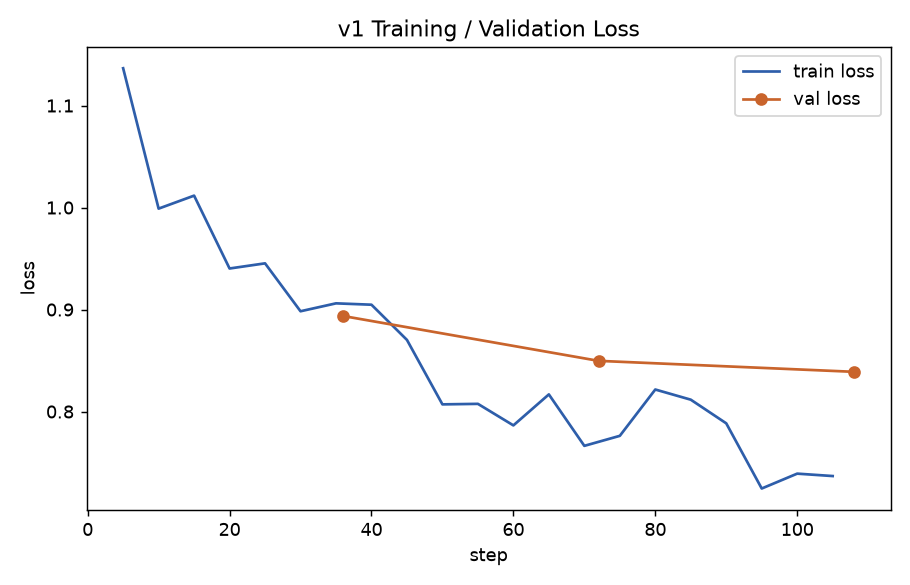

In [7]:
img_path = os.path.join("..", "img", "v1_training_loss.png")
plot_loss_curves(trainer.state.log_history, img_path, title="v1 Training / Validation Loss")
save_json(trainer.state.log_history, os.path.join(RESULTS_DIR, "task3_v1_log_history.json"))
print("Saved", img_path)
from IPython.display import Image, display
display(Image(filename=img_path))

## Save the Adapter (v1)

In [8]:
os.makedirs(ADAPTER_V1_DIR, exist_ok=True)
model.save_pretrained(ADAPTER_V1_DIR)
tokenizer.save_pretrained(ADAPTER_V1_DIR)
print("Saved adapter to", ADAPTER_V1_DIR)


Saved adapter to D:\PostGraduationProjects\Banking-Assistant-SLM-Finetuning\models\novabank-slm-lora-v1


## Inference Demonstration Using the Saved Adapter

Reload the base model fresh + attach the saved v1 adapter (exactly how it would be loaded for
deployment or by Notebook 04/05), and run one benchmark prompt end-to-end as a sanity check.

In [9]:
from src.model_utils import load_lora_adapter

demo_base, demo_tokenizer = load_causal_lm(SLM_MODEL_ID, quantize_4bit=True)
v1_model = load_lora_adapter(demo_base, ADAPTER_V1_DIR)
v1_model.eval()

benchmark = load_benchmark(BENCHMARK_PATH)
demo_prompt = benchmark[0]["prompt"]
prompt_text = format_chat_prompt(demo_tokenizer, demo_prompt, SYSTEM_PROMPT)
demo_response = generate_response(v1_model, demo_tokenizer, prompt_text, **GENERATION_KWARGS)
print("Q:", demo_prompt)
print("v1 response:", demo_response)


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Q: How do I activate a new debit card I just received from NovaBank?
v1 response: Hello! Welcome to our team of dedicated customer service representatives. We're here to assist you in activating your newly received debit card. Here's what you need to do:

1. Visit our website at www.novabank.com.
2. Log in to your account using your credentials.
3. Navigate to the "Debit Cards" or "Account Management" section.
4. Look for an option that says "Activate Card" or something similar.
5. Follow the instructions provided on the page to complete the activation process.

If you encounter any difficulties during this process, please don't hesitate to reach out to our live chat or call us at 1-800-555-0199. Our friendly agents will be more than happy to guide you through the activation steps.

Have a great day!


## Conclusion

- Fine-tuned `Qwen/Qwen2.5-1.5B-Instruct` with LoRA (r=8, alpha=16) on 4-bit quantised base weights
  (QLoRA-style), producing **Version 1 (v1)**.
- Efficiency evidence: trainable-parameter count/%, peak GPU memory during training, and why full
  fine-tuning would not fit the same budget -- all recorded in
  `results/task3_efficiency_summary.json`.
- Training configuration and 1-2 line justifications documented above; loss curves saved to
  `img/v1_training_loss.png`.
- Adapter saved to `models/novabank-slm-lora-v1/`; inference demonstrated by reloading it fresh.

**Next notebook:** `04_diagnose_improve_v2.ipynb` runs v1 against the frozen benchmark and a validation
sample to diagnose concrete weaknesses, then makes 1-2 targeted, evidence-linked changes to produce v2.